# Đồ án môn học: Khai phá dữ liệu trong doanh nghiệp (DS317)

**Dataset:** Electronics Sales Dataset (B.Tech style)


## 0. Thiết lập môi trường


In [1]:
import sys, os
os.chdir("../..")  # dam bao working directory la project/
sys.path.insert(0, "src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

import preprocessing, eda, customer_segmentation, return_prediction, sales_forecasting, market_basket

print("Da nap tat ca cac module xu ly.")

Da nap tat ca cac module xu ly.


## 1. Tổng quan dữ liệu gốc (26 bảng)

Các nhóm bảng chính: Bán hàng, Sản phẩm, Khách hàng & địa lý, Mua hàng & kho, Khuyến mãi & kênh bán.


In [2]:
dfs, dedup_stats = preprocessing.load_raw()
dq = preprocessing.data_quality_report(dfs)
display(dq)
print("So dong trung lap da duoc khu trong buoc doc du lieu:", dedup_stats)

   Da khu trung lap dong hoan toan: {'SalesOrders': 845, 'Customers': 368, 'Products': 1, 'CustomerReturns': 25, 'Shipments': 371}


,Bang,SoDong,SoCot,SoDongTrungLap,TyLeThieuTB(%)
0,InventoryMovements,961048,15,0,37.97
1,SalesOrderLines,579572,9,0,10.51
2,SalesOrders,321732,8,0,8.37
3,Payments,308779,8,0,20.49
4,Shipments,141775,9,0,8.26
5,Customers,140000,5,0,0.16
6,PurchaseReceiptLines,64329,5,0,0.00
7,PurchaseOrderLines,59088,7,0,0.00
8,CustomerReturns,23765,11,0,12.24
9,PurchaseReceipts,22742,3,0,0.00


So dong trung lap da duoc khu trong buoc doc du lieu: {'SalesOrders': 845, 'Customers': 368, 'Products': 1, 'CustomerReturns': 25, 'Shipments': 371}


**Nhận xét:** Đã loại bỏ các dòng trùng lặp ở các bảng SalesOrders, Shipments, Customers, CustomerReturns.


In [3]:
miss = preprocessing.missing_by_column(dfs)
display(miss[miss["TyLeThieu(%)"] > 20])

,Bang,Cot,TyLeThieu(%)
20,CustomerReturns,RefundAmount,36.57
21,CustomerReturns,RefundDate,36.57
22,CustomerReturns,RefundStatus,36.57
37,InventoryMovements,PurchaseReturnID,99.91
38,InventoryMovements,AdjustmentReason,98.94
36,InventoryMovements,CustomerReturnID,97.23
34,InventoryMovements,PurchaseReceiptLineID,93.31
31,InventoryMovements,ToLocationID,59.56
33,InventoryMovements,ToCondition,59.56
35,InventoryMovements,SalesOrderLineID,42.14


## 2. Tiền xử lý và tích hợp dữ liệu


In [4]:
dim_sku = preprocessing.build_dim_product(dfs)
dim_cust = preprocessing.build_dim_customer(dfs)
fact_raw = preprocessing.build_sales_fact(dfs, dim_sku, dim_cust)
fact, clean_stats = preprocessing.clean_sales_fact(fact_raw)
display(pd.DataFrame([clean_stats]))
print("Kich thuoc bang fact sau xu ly:", fact.shape)
fact.head(3)

,SoDongGoc,LoaiDoThieuGia,LoaiDoOutlierGia,LoaiDoOutlierNgay,SoDongConLai,TyLeKhachVangLai(%)
0,579572,0,1095,52,578425,25.61


Kich thuoc bang fact sau xu ly: (578425, 53)


,SalesOrderLineID,SalesOrderID,LineNumber,SKU_ID,Quantity,RegularUnitPrice,ActualSellingPrice,UnitCostAtSale,PromotionID,OrderDate,CustomerID,SalesChannelID,SalesLocationID,OrderStatus,FulfillmentMethod,ShippingFeeAmount,ProductID,ColorName,StorageGB,MemoryGB,BrandID,BrandName,SubcategoryID,SubcategoryName,CategoryID,CategoryName,ModelName,AgeBand,GovernorateName,CustomerSinceDate,ChannelName,ChannelRole,LocationID,LocationName,LocationType,GovernorateID,PromotionName,PromotionType,HasPromotion,ReturnQuantity,ReturnReason,ReturnOutcome,IsReturned,Revenue,RegularRevenue,DiscountAmount,DiscountPct,Profit,OrderYear,OrderMonth,OrderYearMonth,OrderDayOfWeek,OrderQuarter
0,SOL0000009,ORD0000005,1,SKU0000563,1,31375.82,31375.82,NaN,NaN,2023-07-01,CUS0011425,CHN0000002,NaN,Cancelled,Store Pickup,0.0,PRD0000317,Pink,NaN,NaN,BRD0000048,Samsung,SUB0000029,Refrigerators,CAT0000005,Large Home Appliances,Samsung Refrigerators Model 002,35-44,Port Said,2023-04-05,Website,Main e-commerce channel,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,31375.82,31375.82,0.0,0.0,NaN,2023,7,2023-07,Saturday,3
1,SOL0000010,ORD0000005,2,SKU0000853,1,3407.59,3407.59,NaN,NaN,2023-07-01,CUS0011425,CHN0000002,NaN,Cancelled,Store Pickup,0.0,PRD0000539,Green,NaN,NaN,BRD0000064,Xiaomi,SUB0000058,Routers,CAT0000008,Networking & Smart Home,Xiaomi Routers Model 002,35-44,Port Said,2023-04-05,Website,Main e-commerce channel,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,3407.59,3407.59,0.0,0.0,NaN,2023,7,2023-07,Saturday,3
2,SOL0000011,ORD0000005,3,SKU0000452,1,354.32,354.32,NaN,NaN,2023-07-01,CUS0011425,CHN0000002,NaN,Cancelled,Store Pickup,0.0,PRD0000241,Red,NaN,NaN,BRD0000060,UGREEN,SUB0000019,Cables,CAT0000003,Accessories & Peripherals,UGREEN Cables Model 001,35-44,Port Said,2023-04-05,Website,Main e-commerce channel,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,354.32,354.32,0.0,0.0,NaN,2023,7,2023-07,Saturday,3


## 3. Khám phá dữ liệu (EDA)


In [5]:
summary = eda.run_eda(fact)
display(pd.DataFrame([summary]).T.rename(columns={0: "Gia tri"}))

Da xuat 15 bieu do EDA vao outputs/figures
{'TongSoDonHang': 321438, 'TongSoKhachHang': 135731, 'TongSoSanPham(SKU)': 871, 'TongDoanhThu(Completed)': np.float64(8879681042.82), 'DoanhThuTrungBinh/Don': np.float64(28783.966763762022), 'TyLeHuyDon(%)': np.float64(4.026904099701965), 'TyLeTraHang(%)': np.float64(4.1009638241777235), 'KhoangThoiGian': '2023-07-01 - 2025-12-31'}


,Gia tri
TongSoDonHang,321438
TongSoKhachHang,135731
TongSoSanPham(SKU),871
TongDoanhThu(Completed),8879681042.82
DoanhThuTrungBinh/Don,28783.966764
TyLeHuyDon(%),4.026904
TyLeTraHang(%),4.100964
KhoangThoiGian,2023-07-01 - 2025-12-31


### 3.1 Trạng thái đơn hàng & xu hướng doanh thu


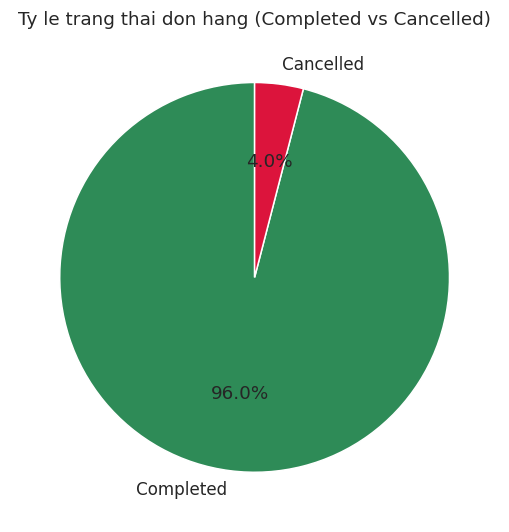

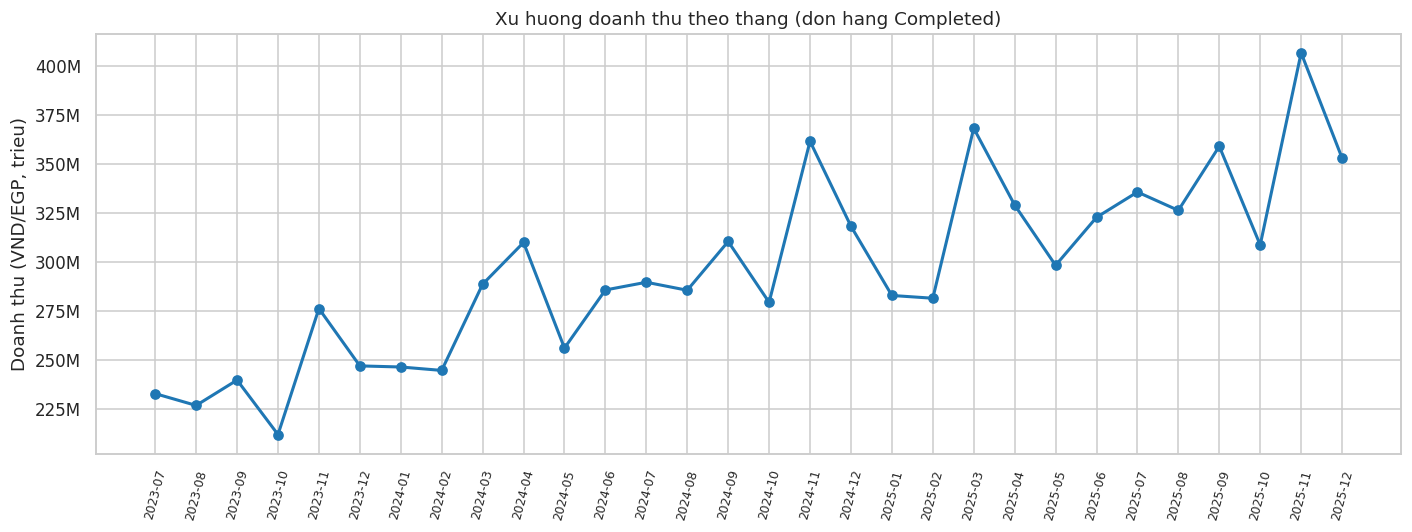

In [6]:
display(Image("outputs/figures/01_order_status_pie.png"))
display(Image("outputs/figures/02_monthly_revenue_trend.png"))

**Nhận xét:** Tỷ lệ huỷ đơn ~4%, doanh thu đạt đỉnh vào tháng 11 hàng năm.


### 3.2 Doanh thu theo ngành hàng, thương hiệu, kênh bán


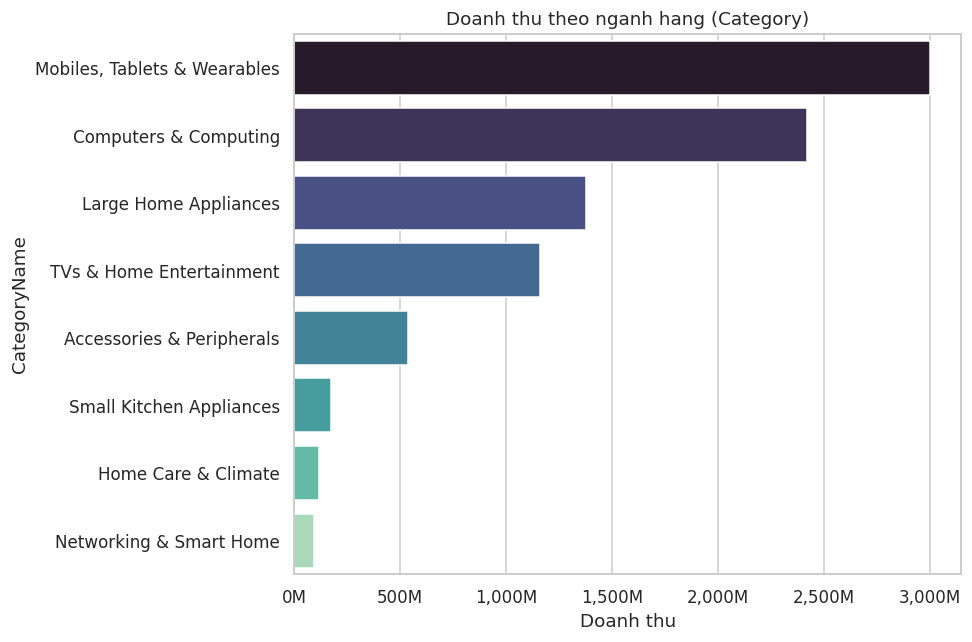

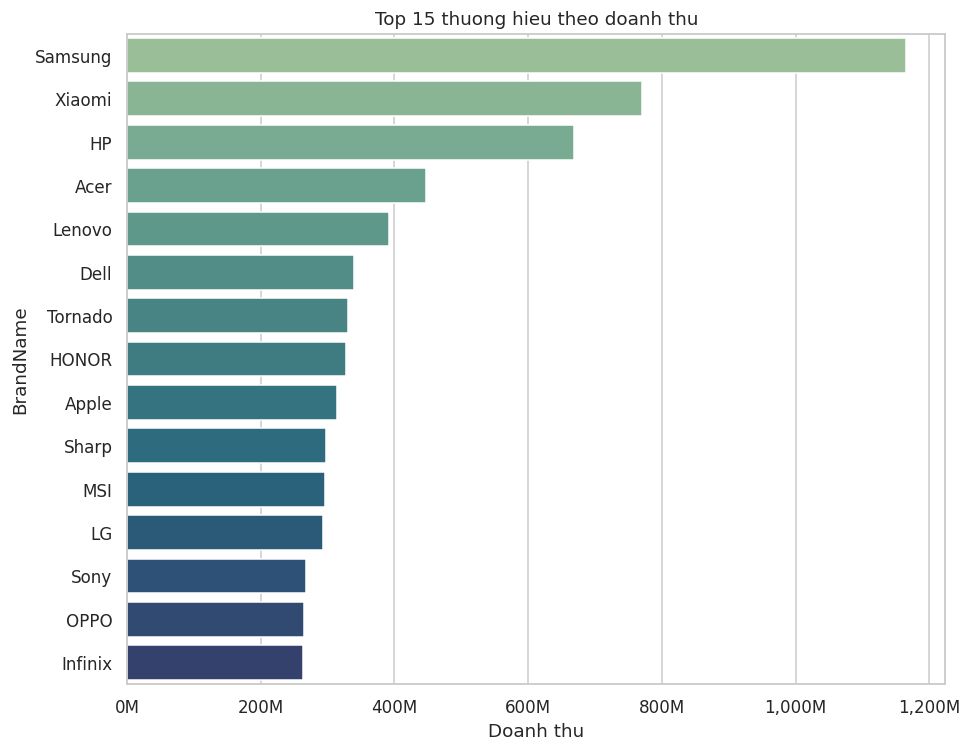

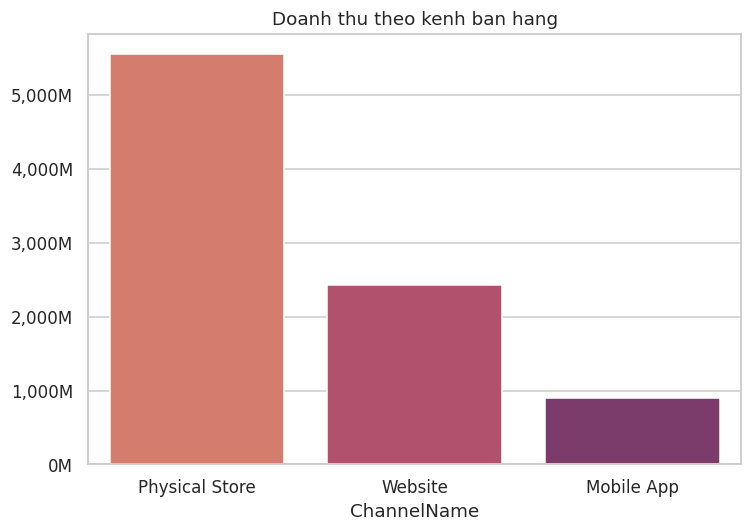

In [7]:
display(Image("outputs/figures/03_revenue_by_category.png"))
display(Image("outputs/figures/04_top_brands_revenue.png"))
display(Image("outputs/figures/05_revenue_by_channel.png"))

### 3.3 Đặc điểm khách hàng & khu vực địa lý


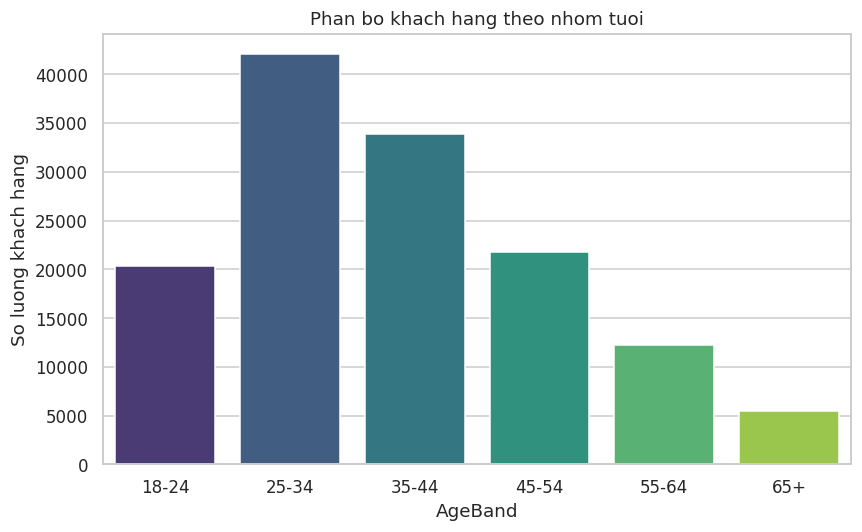

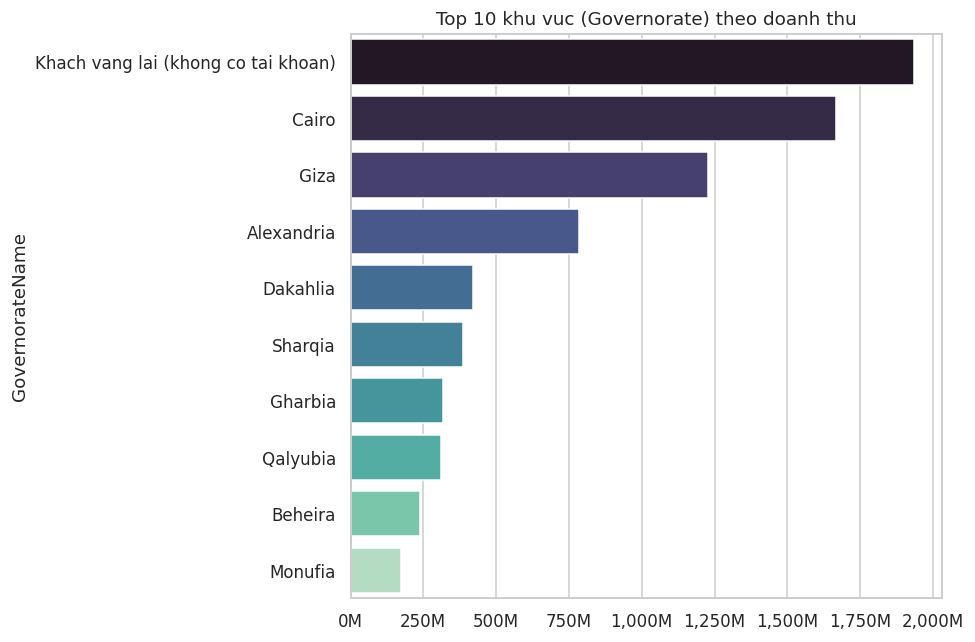

In [8]:
display(Image("outputs/figures/06_customer_age_distribution.png"))
display(Image("outputs/figures/07_revenue_by_governorate.png"))

### 3.4 Phân phối giá & tương quan các biến số


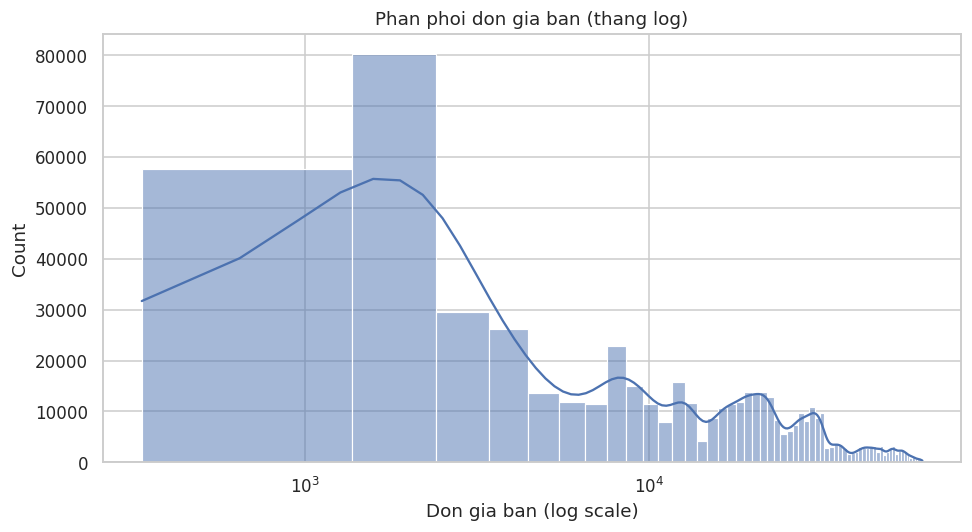

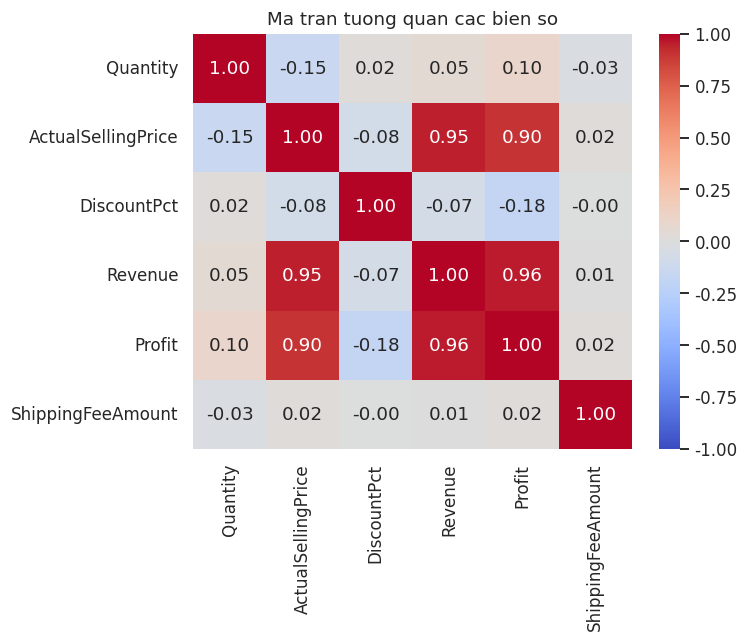

In [9]:
display(Image("outputs/figures/08_price_distribution.png"))
display(Image("outputs/figures/12_correlation_matrix.png"))

### 3.5 Phân tích trả hàng (Returns)


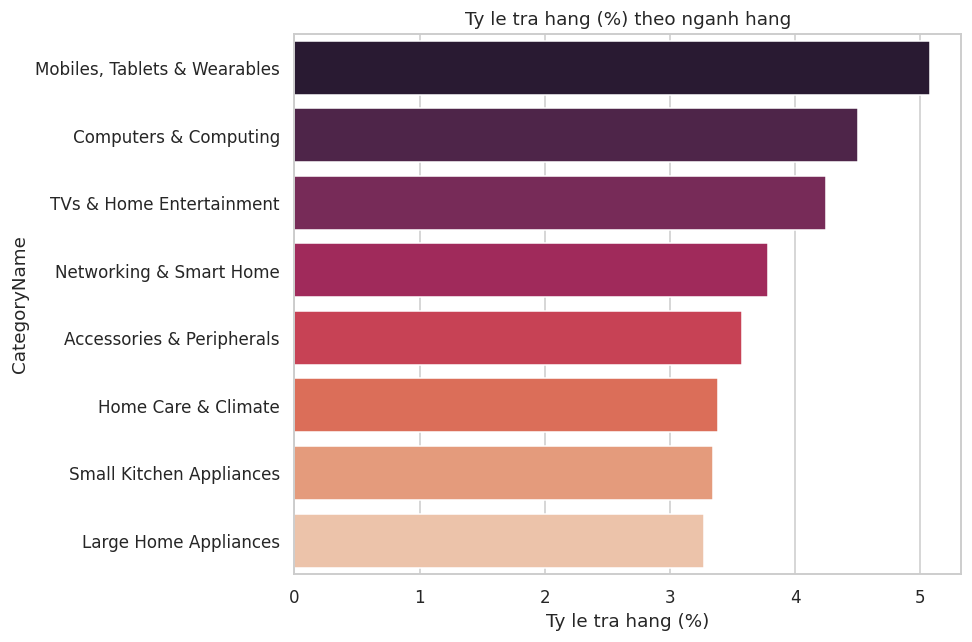

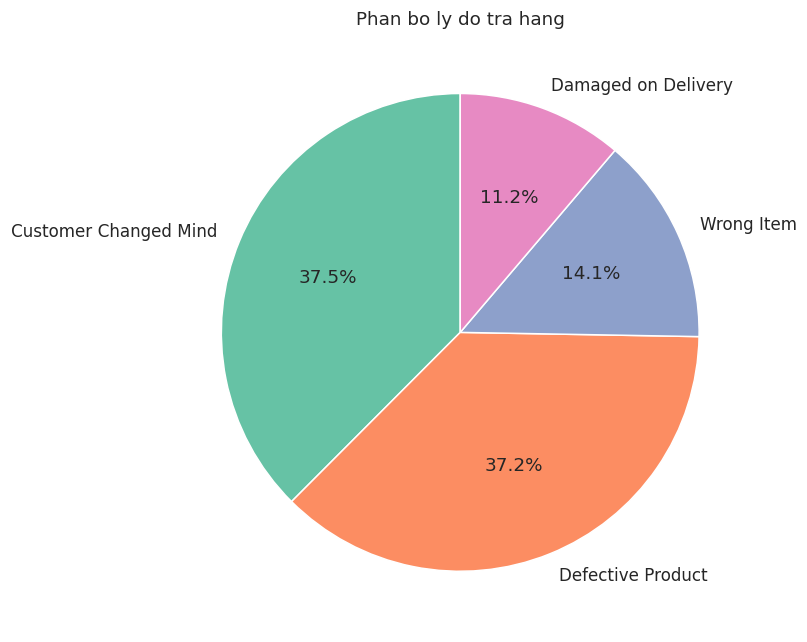

In [10]:
display(Image("outputs/figures/09_return_rate_by_category.png"))
display(Image("outputs/figures/10_return_reasons.png"))

### 3.6 Các phân tích khác


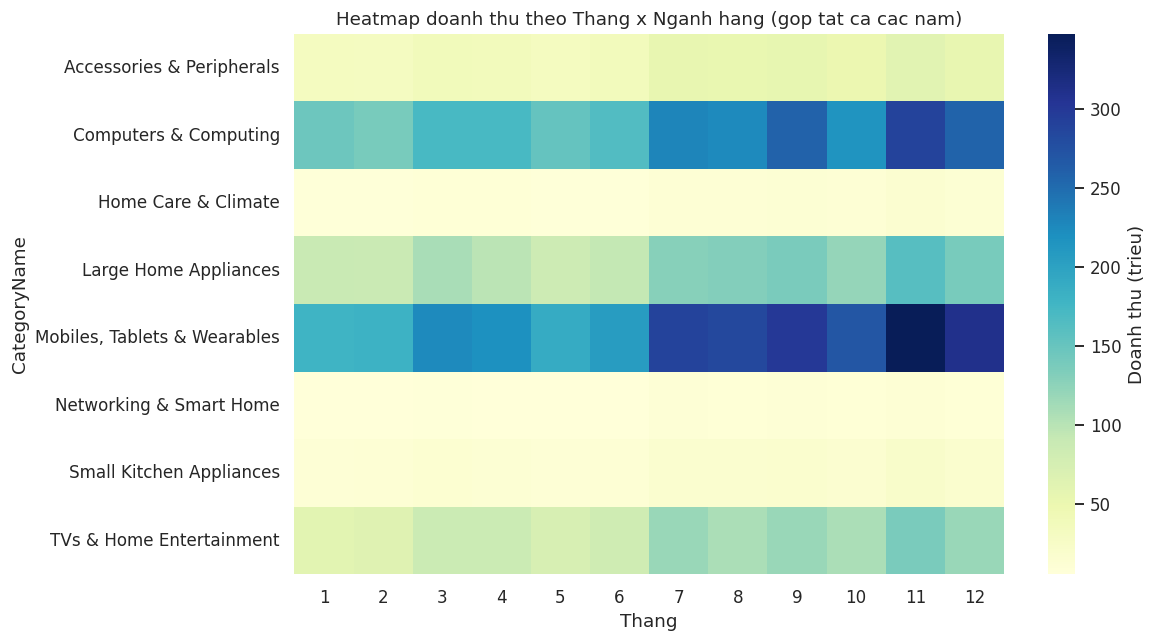

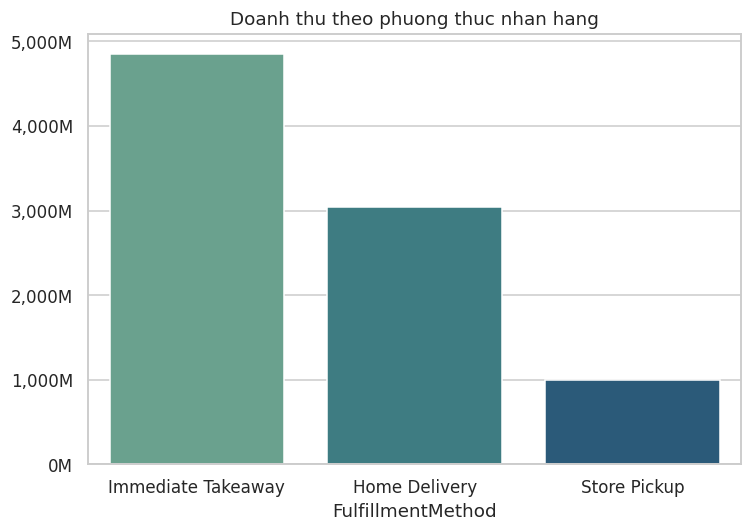

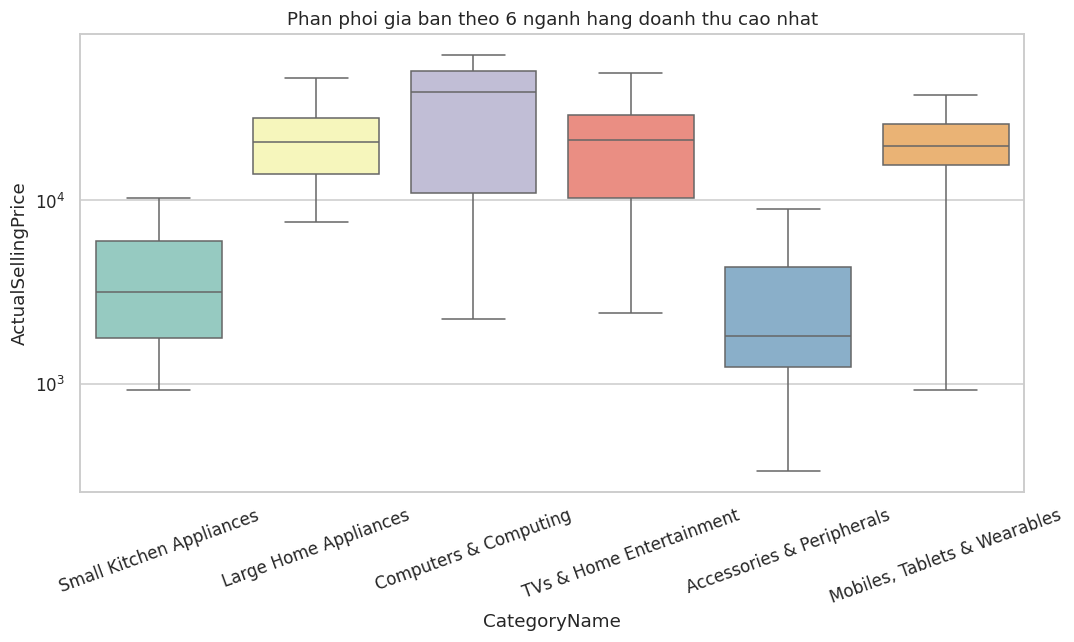

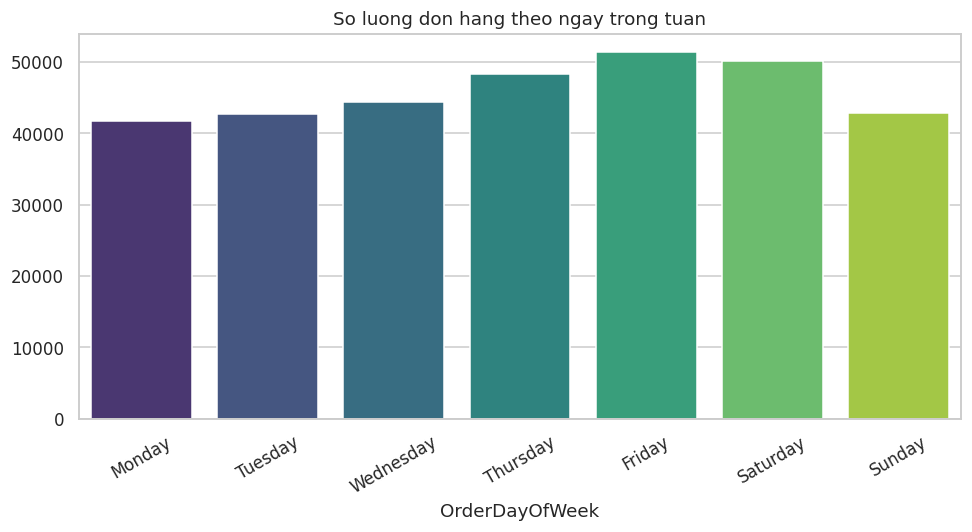

In [11]:
display(Image("outputs/figures/11_heatmap_month_category.png"))
display(Image("outputs/figures/13_revenue_by_fulfillment.png"))
display(Image("outputs/figures/14_price_boxplot_by_category.png"))
display(Image("outputs/figures/15_orders_by_dayofweek.png"))

## 4. Bài toán 1 - Phân cụm: Phân khúc khách hàng (RFM + K-Means)


>> Tinh toan RFM...


   So khach hang co don hang hop le: 132193
>> Tim so cum toi uu (Elbow + Silhouette)...


   So cum toi uu duoc chon: k=3
   Silhouette scores: {2: 0.3874259703603853, 3: 0.3994318909638608, 4: 0.39522232894420495, 5: 0.4012389208653034, 6: 0.3992311106048709, 7: 0.39273172940875484, 8: 0.3530514381007446}


   Silhouette score cuoi cung: 0.3994


>> Ho so cac phan khuc:
                                          Recency  Frequency  Monetary  AvgOrderValue  SoLuongKH
SegmentName                                                                                     
Khach hang VIP / Trung thanh                414.0        2.8   90972.2        33552.4      42750
Khach hang tiem nang / Trung binh           125.5        1.3   41821.9        33894.7      14609
Khach hang gia tri thap / Nguy co roi bo    607.0        1.0   30089.4        29700.4      74173


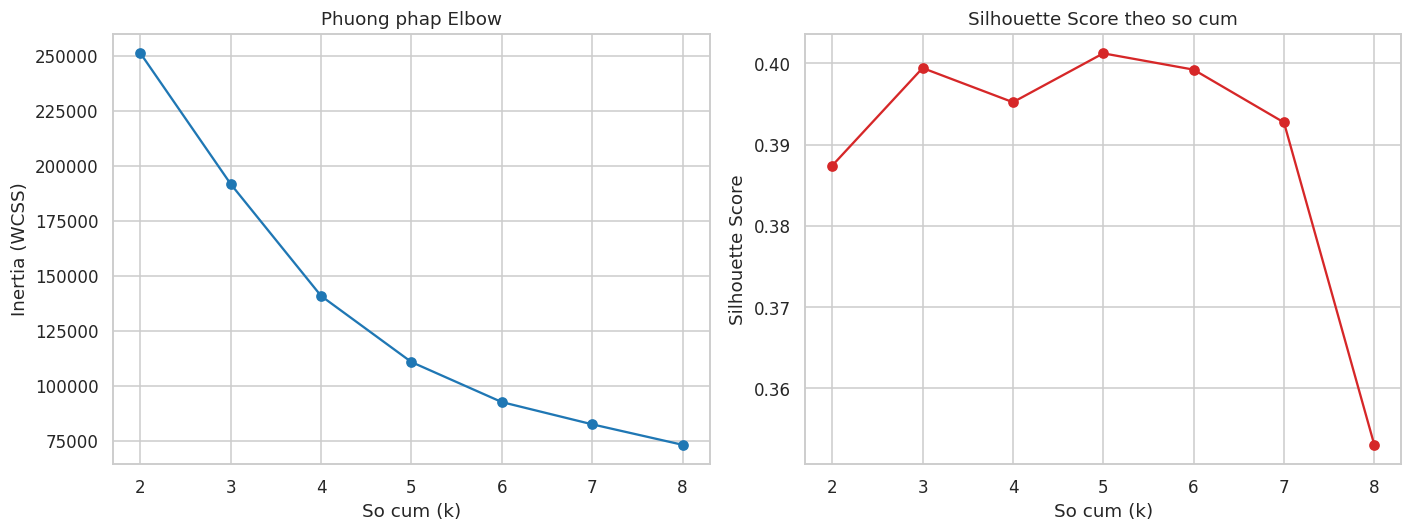

In [12]:
rfm, profile, sil = customer_segmentation.run_segmentation(fact)
display(Image("outputs/figures/16_kmeans_elbow_silhouette.png"))

**Đánh giá:** Silhouette Score đạt xấp xỉ 0.40 với k=3.


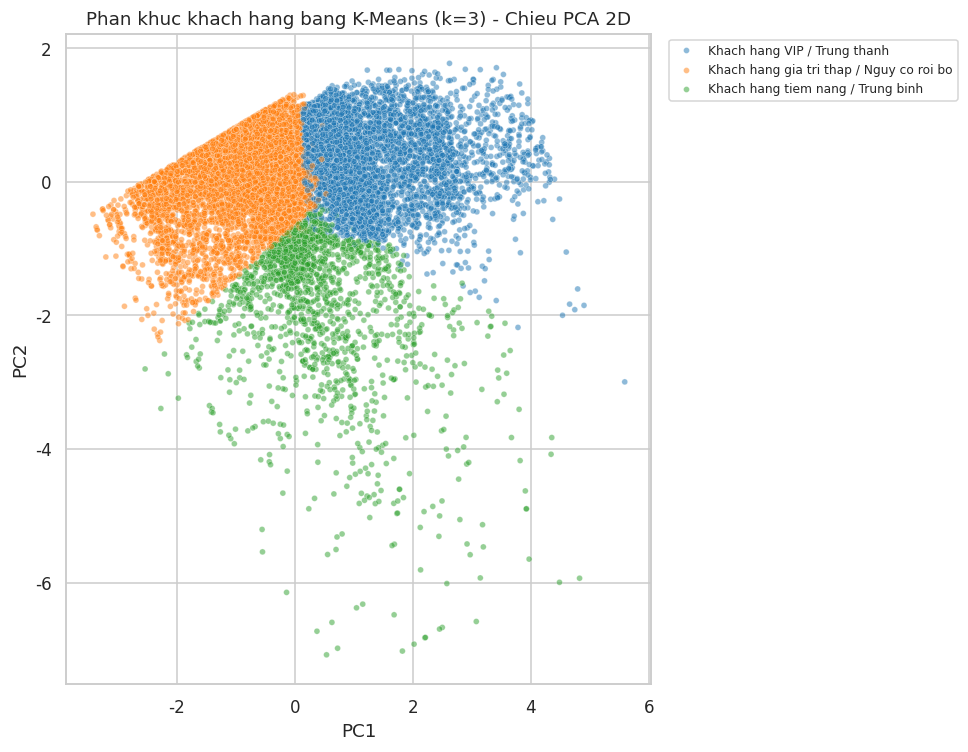

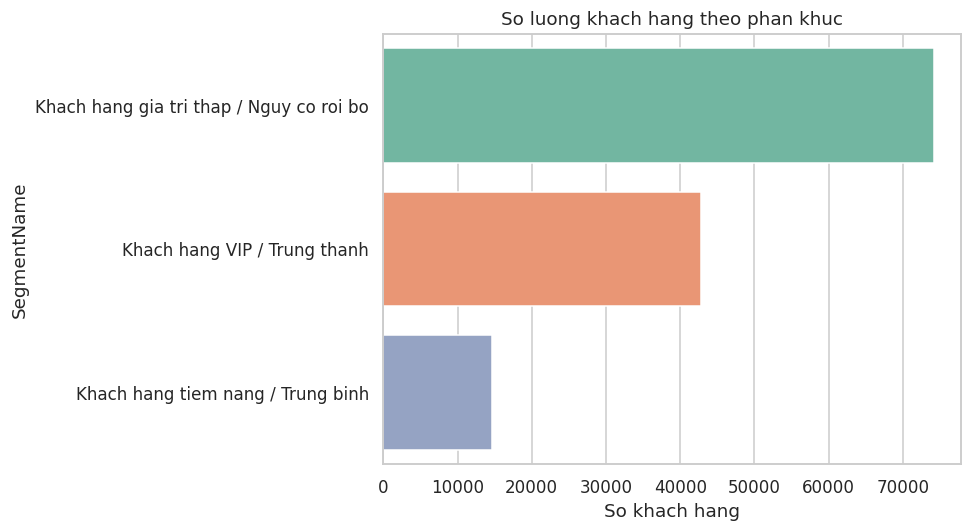

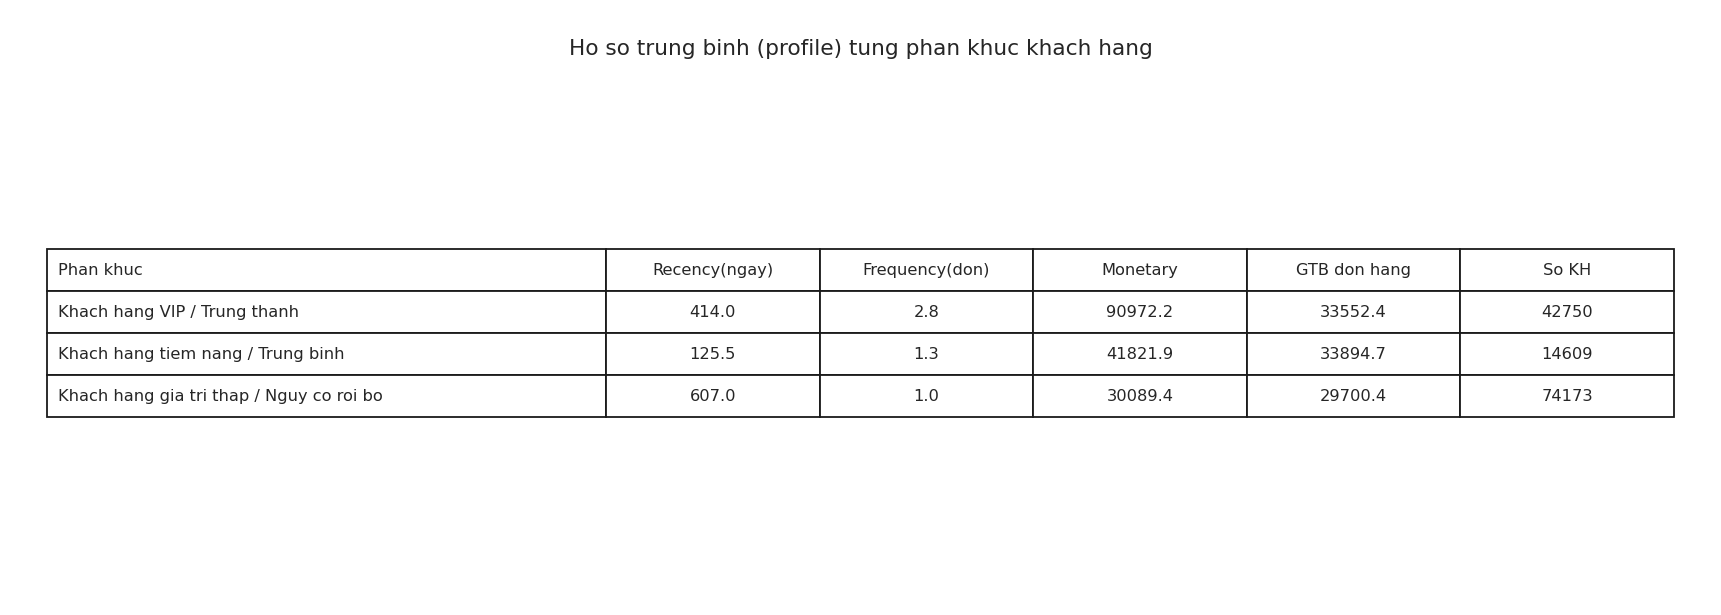

,Recency,Frequency,Monetary,AvgOrderValue,SoLuongKH
SegmentName,,,,,
Khach hang VIP / Trung thanh,414.0,2.8,90972.2,33552.4,42750
Khach hang tiem nang / Trung binh,125.5,1.3,41821.9,33894.7,14609
Khach hang gia tri thap / Nguy co roi bo,607.0,1.0,30089.4,29700.4,74173


In [13]:
display(Image("outputs/figures/17_customer_segments_pca.png"))
display(Image("outputs/figures/18_segment_customer_count.png"))
display(Image("outputs/figures/19_segment_profile_table.png"))
display(profile)

**Kết quả phân cụm:** Hồ sơ 3 phân khúc khách hàng theo RFM.


## 5. Bài toán 2 - Phân loại: Dự đoán khả năng trả hàng


>> Chuan bi du lieu cho bai toan phan loai...


   Kich thuoc du lieu: (554995, 13)
   Ty le lop duong (tra hang): 0.04274092559392427


   Train: (416246, 12), Test: (138749, 12)
>> Huan luyen Logistic Regression...


>> Huan luyen Random Forest...


>> Huan luyen Gradient Boosting...


                 Model       AUC        F1  Precision    Recall  Accuracy
1        Random Forest  0.545006  0.091018   0.050571  0.454637  0.611896
2    Gradient Boosting  0.544809  0.000000   0.000000  0.000000  0.957239
0  Logistic Regression  0.544619  0.090237   0.049362  0.524789  0.547744
>> Mo hinh tot nhat: Random Forest


,Model,AUC,F1,Precision,Recall,Accuracy
1,Random Forest,0.545006,0.091018,0.050571,0.454637,0.611896
2,Gradient Boosting,0.544809,0.000000,0.000000,0.000000,0.957239
0,Logistic Regression,0.544619,0.090237,0.049362,0.524789,0.547744


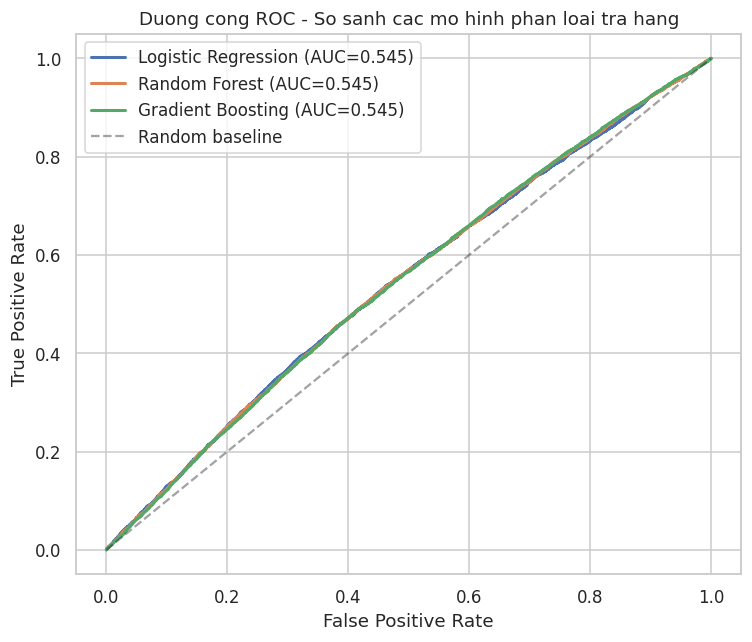

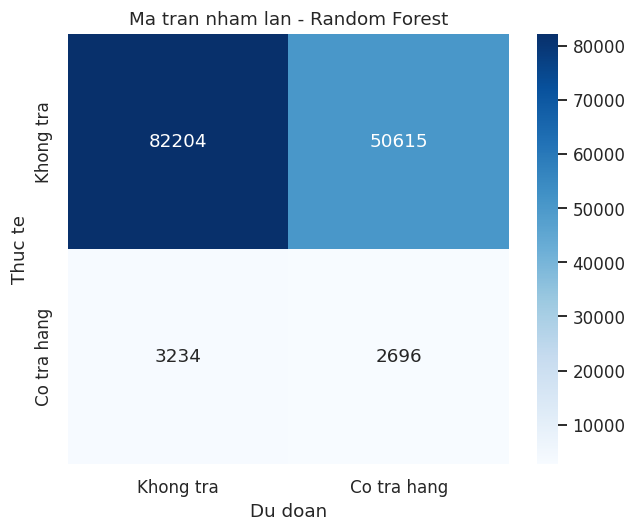

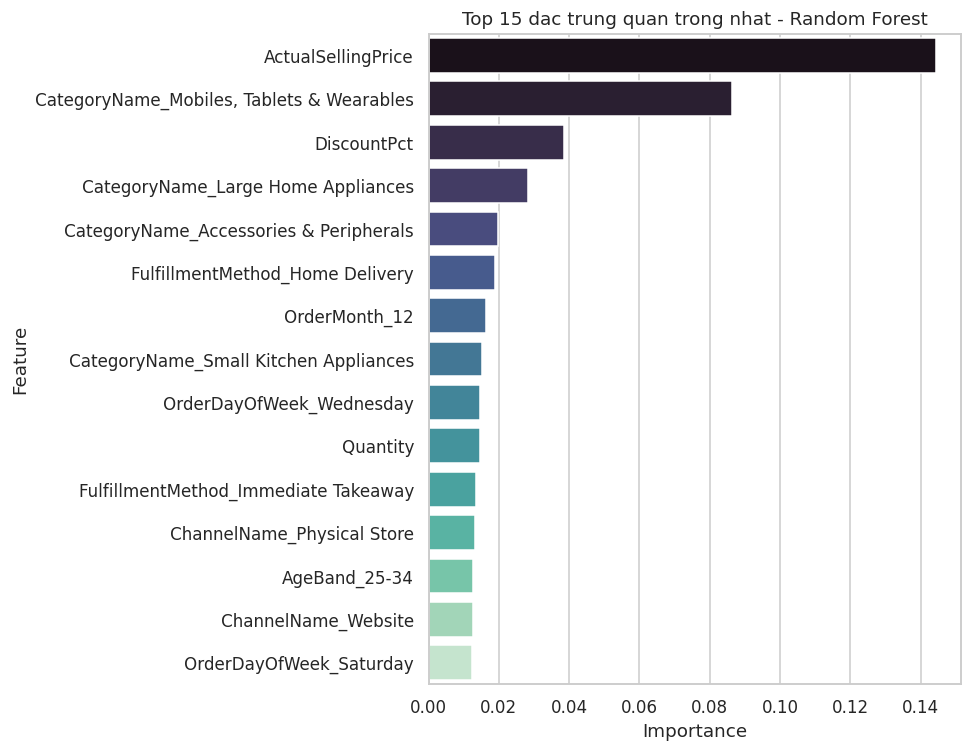

In [14]:
clf_results, best_clf = return_prediction.run_classification(fact)
display(clf_results)
display(Image("outputs/figures/20_classification_roc_curves.png"))
display(Image("outputs/figures/21_confusion_matrix_best_model.png"))
display(Image("outputs/figures/23_feature_importance.png"))

**Nhận xét:** AUC ~ 0.55 cho thấy các đặc trưng tại thời điểm bán hàng chưa đủ để dự đoán hành vi trả hàng.


## 6. Bài toán 3 - Hồi quy & Chuỗi thời gian: Dự báo doanh thu

### 6.1 Dự báo doanh thu theo tháng (Time Series)


>> Xay dung chuoi doanh thu theo thang...


   So thang du lieu: 30, dung cho huan luyen: 27
               Model           MAE          RMSE    MAPE(%)        R2
2      Random Forest  3.346786e+07  4.170164e+07   9.113712 -0.807234
3  Gradient Boosting  3.513890e+07  4.552860e+07   9.477386 -1.154153
1   Ridge Regression  3.635027e+07  4.241410e+07  11.047135 -0.869514
0  Linear Regression  3.679777e+07  4.307889e+07  11.191620 -0.928578
>> Mo hinh du bao tot nhat: Random Forest


>> Du bao doanh thu 3 thang tiep theo: [np.float64(312757109.0), np.float64(312711586.0), np.float64(314704163.0)]


,Model,MAE,RMSE,MAPE(%),R2
2,Random Forest,3.346786e+07,4.170164e+07,9.113712,-0.807234
3,Gradient Boosting,3.513890e+07,4.552860e+07,9.477386,-1.154153
1,Ridge Regression,3.635027e+07,4.241410e+07,11.047135,-0.869514
0,Linear Regression,3.679777e+07,4.307889e+07,11.191620,-0.928578


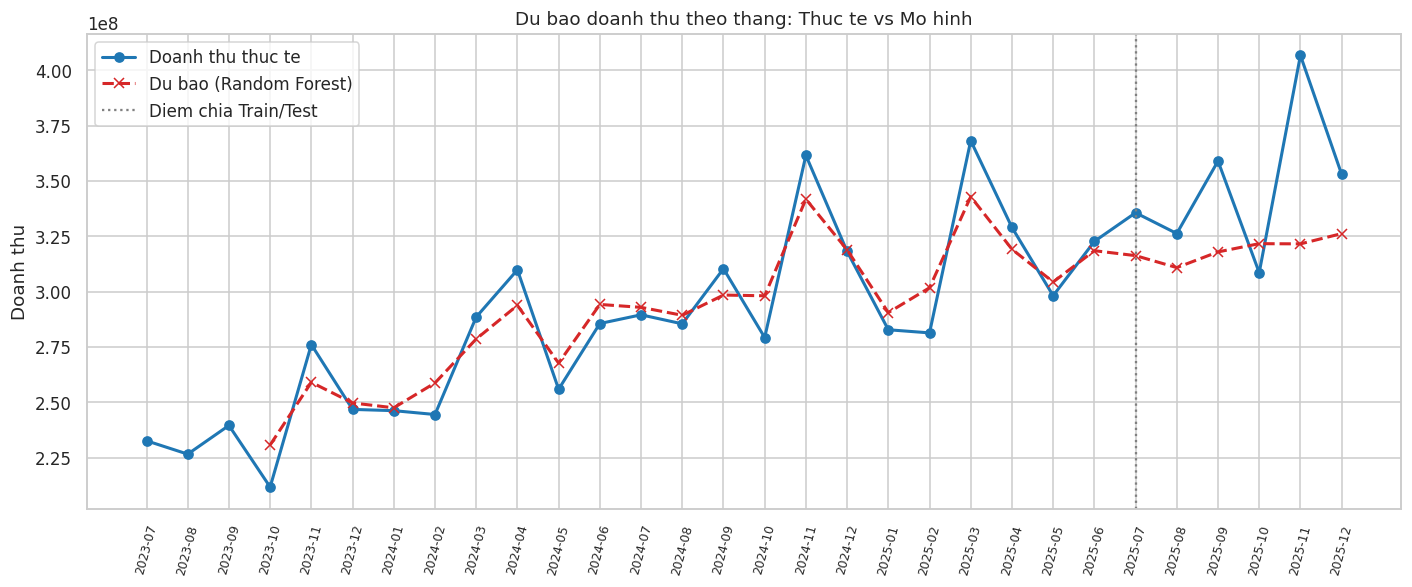

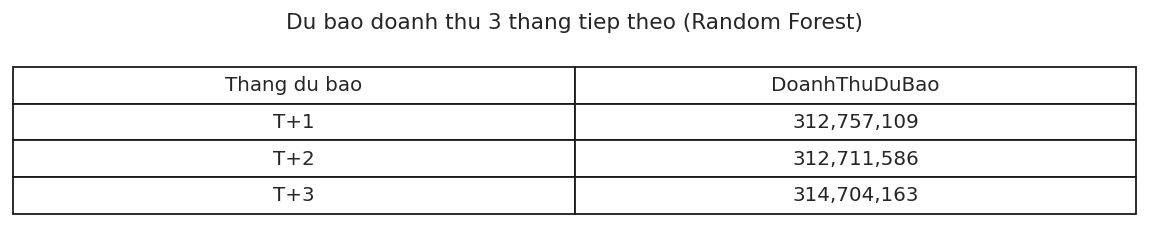

In [15]:
ts_results, future_preds = sales_forecasting.run_time_series_forecast(fact)
display(ts_results)
display(Image("outputs/figures/24_revenue_forecast_actual_vs_predicted.png"))
display(Image("outputs/figures/25_revenue_forecast_next3months.png"))

### 6.2 Hồi quy giá trị dòng hàng (Order Value Regression)


>> Chuan bi du lieu hoi quy gia tri dong hang...


                    Model          MAE         RMSE        R2
2  Hist Gradient Boosting  4714.212413  6881.413876  0.769655
0       Linear Regression  5404.844961  7729.553386  0.709375
1           Random Forest  5532.052809  8046.649328  0.685041


,Model,MAE,RMSE,R2
2,Hist Gradient Boosting,4714.212413,6881.413876,0.769655
0,Linear Regression,5404.844961,7729.553386,0.709375
1,Random Forest,5532.052809,8046.649328,0.685041


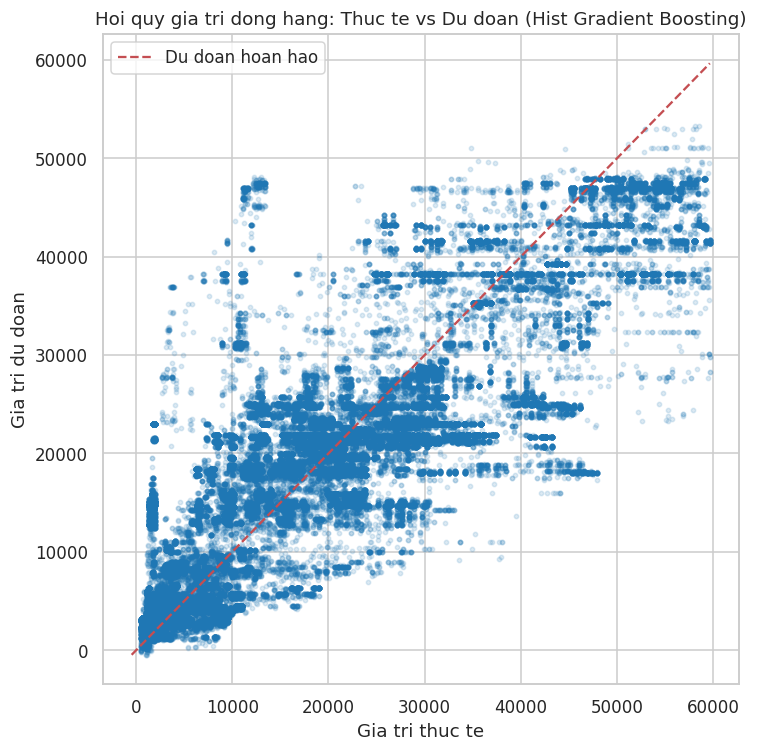

In [16]:
reg_results = sales_forecasting.run_order_value_regression(fact)
display(reg_results)
display(Image("outputs/figures/26_order_value_regression_scatter.png"))

**Nhận xét:** Hist Gradient Boosting đạt R² ~ 0.77 cho bài toán hồi quy giá trị dòng hàng.


## 7. Bài toán 4 - Luật kết hợp: Phân tích giỏ hàng (Apriori)


>> Xay dung du lieu gio hang theo Nganh hang (Subcategory)...


   So don hang co >=2 nganh hang khac nhau: 162631
>> Chay thuat toan Apriori tim tap pho bien...


   So tap pho bien tim duoc: 254
>> Tim duoc 168 luat ket hop (lift >= 1.0)
          NeuMua(Antecedent)       ThiCungMua(Consequent)  Support  Confidence      Lift
                 Desktop PCs                    Keyboards 0.004938    0.283846 16.896830
                   Keyboards                  Desktop PCs 0.004938    0.293924 16.896830
                    Monitors                  Desktop PCs 0.004968    0.293391 16.866222
                 Desktop PCs                     Monitors 0.004968    0.285613 16.866222
             Wi-Fi Extenders           Mesh Wi-Fi Systems 0.004046    0.138760 13.785388
          Mesh Wi-Fi Systems              Wi-Fi Extenders 0.004046    0.401955 13.785388
             Wi-Fi Extenders                      Routers 0.018914    0.648671 13.523149
                     Routers              Wi-Fi Extenders 0.018914    0.394308 13.523149
                     Routers               Smart Lighting 0.004378    0.091270 10.625188
              Smart Lighting      

,NeuMua(Antecedent),ThiCungMua(Consequent),Support,Confidence,Lift
14,Desktop PCs,Keyboards,0.004938,0.283846,16.896830
15,Keyboards,Desktop PCs,0.004938,0.293924,16.896830
18,Monitors,Desktop PCs,0.004968,0.293391,16.866222
19,Desktop PCs,Monitors,0.004968,0.285613,16.866222
42,Wi-Fi Extenders,Mesh Wi-Fi Systems,0.004046,0.138760,13.785388
43,Mesh Wi-Fi Systems,Wi-Fi Extenders,0.004046,0.401955,13.785388
60,Wi-Fi Extenders,Routers,0.018914,0.648671,13.523149
61,Routers,Wi-Fi Extenders,0.018914,0.394308,13.523149
54,Routers,Smart Lighting,0.004378,0.091270,10.625188
55,Smart Lighting,Routers,0.004378,0.509664,10.625188


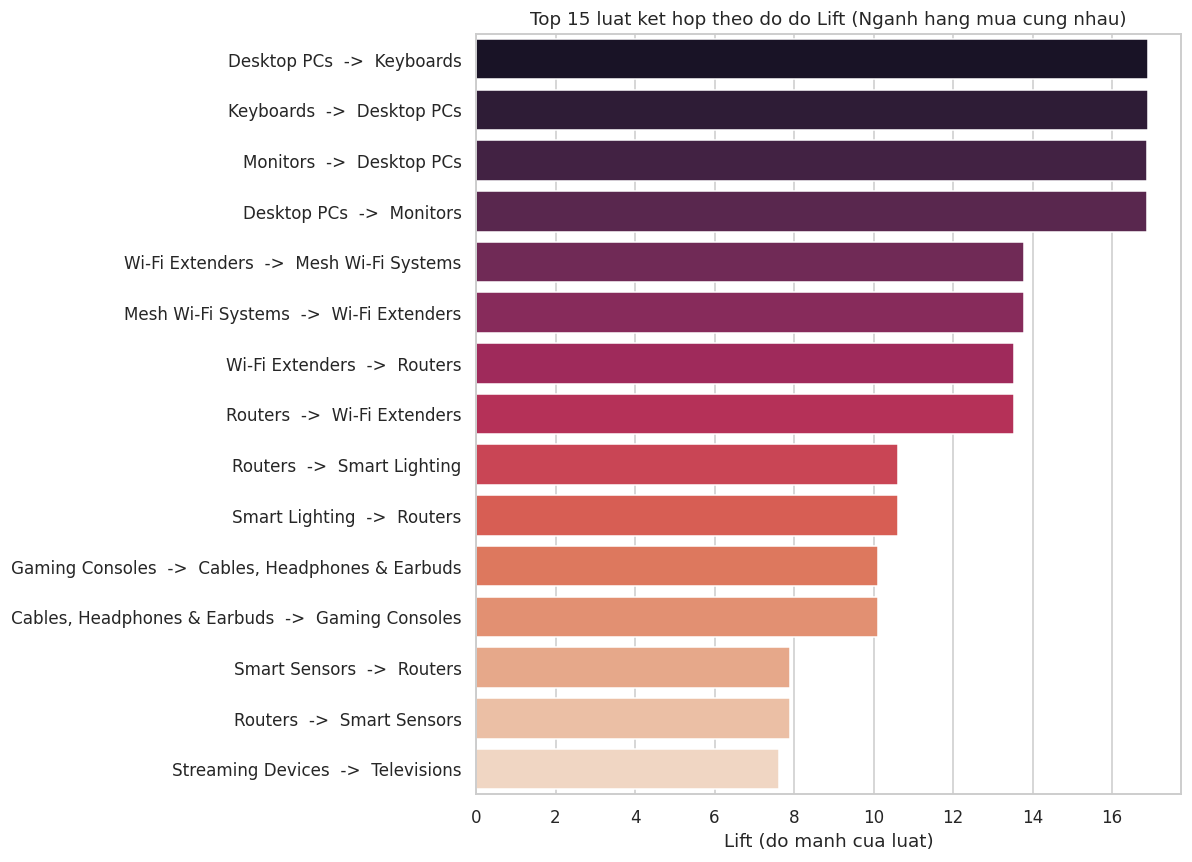

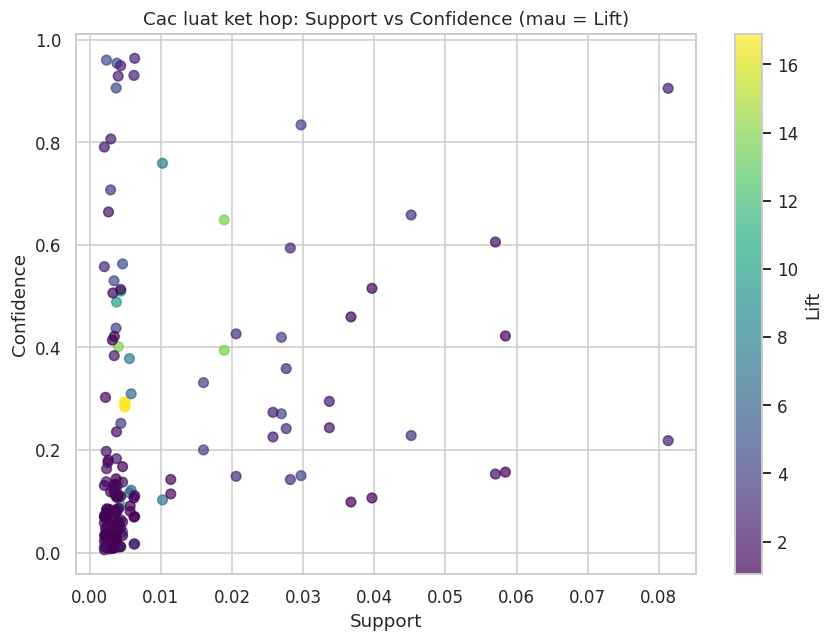

In [17]:
freq_items, rules = market_basket.run_market_basket(fact)
display(rules.head(15))
display(Image("outputs/figures/27_association_rules_top_lift.png"))
display(Image("outputs/figures/28_association_rules_scatter.png"))

**Nhận xét:** Các luật có Lift cao nhất: Desktop PCs - Keyboards - Monitors (Lift ~ 17), Routers - Wi-Fi Extenders (Lift ~ 13.5).


## 8. Tổng kết

| Bài toán | Kỹ thuật | Kết quả chính |
|---|---|---|
| Phân khúc khách hàng | K-Means (RFM) | 3 cụm, Silhouette ≈ 0.40 |
| Dự đoán trả hàng | Random Forest / GBM | AUC ≈ 0.55 |
| Dự báo doanh thu tháng | Random Forest (lag features) | MAPE ≈ 9.1% |
| Hồi quy giá trị đơn hàng | Hist Gradient Boosting | R² ≈ 0.77 |
| Luật kết hợp giỏ hàng | Apriori | 168 luật (lift cao nhất ≈ 17.0) |
